In [ ]:
import xtrack as xt
import json
from class_geometry.ring_geometry.ring_geometry import RingGeometry
import matplotlib.pyplot as plt
import numpy as np
from TrackingRCS import TrackingRCS
from TrackingRCS import plot_emit_2rcs

/home/ls276867/.venvs/xsuite/lib/python3.11/site-packages/numpy/_core/getlimits.py:552: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)
/home/ls276867/.venvs/xsuite/lib/python3.11/site-packages/xplt/hooks.py:31: RuntimeWarning: Failed to register formatters with pint: No module named 'pint'
  warnings.warn(f"Failed to register formatters with pint: {e}", RuntimeWarning)


In [2]:
plt.rc('axes', labelsize=12)     # fontsize of the x and y labels
plt.rc('xtick', labelsize=12)    # fontsize of the tick labels
plt.rc('ytick', labelsize=12)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize

In [6]:
input = {
    'RCS1': {
        'n_turn_rcs' : 17,
        't_acc' : 0.34e-3,
        'sigma_z' : 30.2e-12,
        # 'file_arc' : '/mnt/c/muco/code/lattices/lattice_08_25/line_RCS1_gf_normal_qp_8_arc_v2_chromacorrect.json',
        'file_arc' : '/mnt/c/muco/code/lattices/lattice_08_25/line_RCS1_gf_normal_qp_8_arc_sxt20.json',
        'file_geo' : '/mnt/c/muco/code/lattices/lattice_consolidated_ESPPU/GF_RCS1/para_RCS1_gf_normal_qp__8_arc.json'
    },
    'RCS2': {
        'n_turn_rcs' : 55,
        't_acc' : 1.1e-3,
        'sigma_z' : 22e-12,
        'file_arc' : '/mnt/c/muco/code/lattices/lattice_consolidated_ESPPU/GF_RCS2/line_RCS2_gf_normal_qp_8_arc_v2.json',
        'file_geo' : '/mnt/c/muco/code/lattices/lattice_consolidated_ESPPU/GF_RCS2/para_RCS2_gf_normal_qp__8_arc.json'

    },
    'RCS3': {
        'n_turn_rcs' : 66,
        't_acc' : 2.37e-3,
        'sigma_z' : 14e-12,
        'file_arc' : '/mnt/c/muco/code/lattices/lattice_consolidated_ESPPU/GF_RCS3/line_RCS3_gf_normal_qp_8_arc.json',
        'file_geo' : '/mnt/c/muco/code/lattices/lattice_consolidated_ESPPU/GF_RCS3/para_RCS3_gf_normal_qp__8_arc.json'

    },
    'RCS4': {
        'n_turn_rcs' : 55,
        't_acc' : 6.37e-3,
        'sigma_z' : 10e-12,
        'file_arc' : '/mnt/c/muco/code/lattices/lattice_consolidated_ESPPU/GF_RCS4/line_RCS4_gf_normal_qp_8_arc.json',
        'file_geo' : '/mnt/c/muco/code/lattices/lattice_consolidated_ESPPU/GF_RCS4/para_RCS4_gf_normal_qp__8_arc.json'

    }
}

n_part = 5000
nemitt_x = 25e-6
nemitt_y = 25e-6
nemitt_s = 0.025

In [4]:
input_rcs1 = {
    'RCS1_8arc_noramp_nomEl' : {
        'file_arc' : '/mnt/c/muco/code/lattices/lattice_08_25/line_RCS1_gf_normal_qp_8_arc_v2.json',
        'file_geo' : '/mnt/c/muco/code//lattices/lattice_08_25/para_RCS1_gf_normal_qp__8_arc.json',
        'sigma_z' : 30.2e-12,
        'ramp' : False,
        'label' : r'8a, No ramp, $\epsilon_s$',
        'n_turn_rcs' : 17,
        't_acc' : 0.34e-3,
    },
    'RCS1_8arc_noramp_low_el' : {
        'file_arc' : '/mnt/c/muco/code/lattices/lattice_08_25/line_RCS1_gf_normal_qp_8_arc_v2.json',
        'file_geo' : '/mnt/c/muco/code/lattices/lattice_08_25/para_RCS1_gf_normal_qp__8_arc.json',
        'sigma_z' : 30.2e-12/3,
        'ramp' : False,
        'label' : r'8a, No ramp, $\epsilon_s$/10',
        'n_turn_rcs' : 17,
        't_acc' : 0.34e-3,
    },
    'RCS1_8arc_ramp_low_el' : {
        'file_arc' : '/mnt/c/muco/code/lattices/lattice_08_25/line_RCS1_gf_normal_qp_8_arc_v2.json',
        'file_geo' : '/mnt/c/muco/code/lattices/lattice_08_25/para_RCS1_gf_normal_qp__8_arc.json',
        'sigma_z' : 30.2e-12/3,
        'ramp' : True,
        'label' : r'8a, Ramp, $\epsilon_s$/10',
        'n_turn_rcs' : 17,
        't_acc' : 0.34e-3,
    },
    'RCS1_28arc_noramp_nomEl' : {
        'file_arc' : '/mnt/c/muco/code/lattices/lattice_08_25/line_RCS1_gf_normal_qp_28_arc.json',
        'file_geo' : '/mnt/c/muco/code/lattices/lattice_08_25/para_RCS1_gf_normal_qp__28_arc.json',
        'sigma_z' : 30.2e-12,
        'ramp' : False,
        'label' : r'28a, No ramp, $\epsilon_s$',
        'n_turn_rcs' : 17,
        't_acc' : 0.34e-3,
    },
    'RCS1_28arc_ramp_nomEl' : {
        'file_arc' : '/mnt/c/muco/code/lattices/lattice_08_25/line_RCS1_gf_normal_qp_28_arc.json',
        'file_geo' : '/mnt/c/muco/code/lattices/lattice_08_25/para_RCS1_gf_normal_qp__28_arc.json',
        'sigma_z' : 30.2e-12,
        'ramp' : True,
        'label' : r'28a, Ramp, $\epsilon_s$',
        'n_turn_rcs' : 17,
        't_acc' : 0.34e-3,
    },
}
input = input_rcs1

In [ ]:
rcs_name = 'RCS4'
file_geo = input[rcs_name]['file_geo']
file_arc = input[rcs_name]['file_arc']

file_arc = '/mnt/c/muco/code/lattices/lattices_final_report/RCS4_gf/line_RCS4_gf_normal_qp_32_arc.json'
file_geo = '/mnt/c/muco/code/lattices/lattices_final_report/RCS4_gf/para_RCS4_gf_normal_qp__32_arc.json'

if rcs_name == 'RCS1':
    file_geo = '/mnt/c/muco/code/lattices/lattice_08_25/para_RCS1_gf_normal_qp__8_arc.json'

n_turn_rcs = input[rcs_name]['n_turn_rcs']
t_acc = input[rcs_name]['t_acc']
sigma_z = input[rcs_name]['sigma_z']

line_arc = xt.Line.from_json(file_arc)
rcs = RingGeometry(file_geo)
nb_arc_tot = n_turn_rcs*rcs.nb_arc

Loading line from dict: 100%|██████████| 227/227 [00:00<00:00, 9931.33it/s]

Done loading line from dict.           


In [5]:
method = 'var_ref'
RF_tuning = False
ramp = False
try:
    ramp = input[rcs_name]['ramp']
except:
    ramp = ramp

n_factor = 1
n_range = range(int(nb_arc_tot/n_factor))

n_track = 1

----- Generating particle distribution -----
Emittance x at injection, before 2nd order matching 2.521355764261463e-05
Emittance s at injection 0.026774654265450632
----- Initial particle distribution and separatrix -----


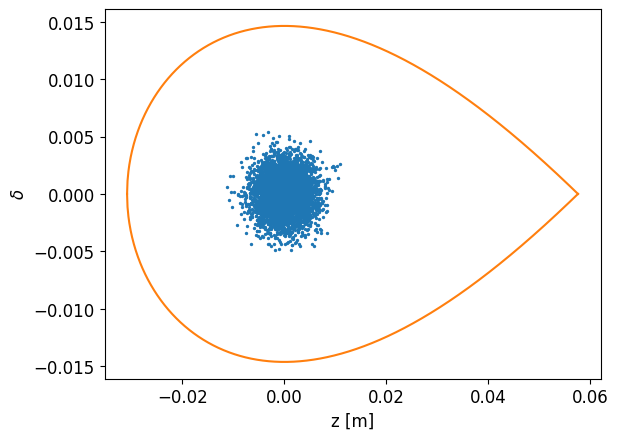

----- Build RCS line -----
----- Insert particle monitors and apertures -----
(View of Marker(), View of Quadrupole(k1=-0.00349, k1s=0, length=4, num_multipole_kicks=np.int64(0), order=np.int64(5), inv_factorial_order=0.00833, knl=[0., 0., 0., 0., 0., 0.], ksl=[0., 0., 0., 0., 0., 0.], edge_entry_active=np.uint64(0), edge_exit_active=np.uint64(0), model='adaptive', integrator='adaptive', radiation_flag=np.int64(0), delta_taper=0, shift_x=0, shift_y=0, shift_s=0, rot_s_rad=0, rot_x_rad=0, rot_y_rad=0, rot_s_rad_no_frame=0, rot_shift_anchor=0), View of ReferenceEnergyIncrease(Delta_p0c=9.94e+08), View of Cavity(length=0, voltage=1.41e+09, frequency=1.3e+09, lag=135, harmonic=0, lag_taper=0, absolute_time=np.int64(0), num_kicks=np.int64(0), model='adaptive', integrator='adaptive', shift_x=0, shift_y=0, shift_s=0, rot_s_rad=0, rot_x_rad=0, rot_y_rad=0, rot_s_rad_no_frame=0, rot_shift_anchor=0), View of Drift(length=60.4, model='adaptive'), View of Quadrupole(k1=0.00384, k1s=0, length=8, nu

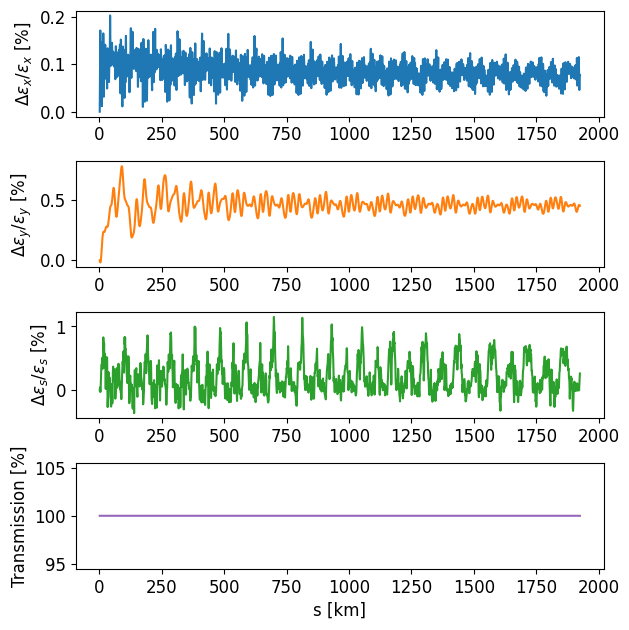

In [6]:
track = TrackingRCS(
    line=line_arc,
    rcs=rcs,
    n_turn_rcs=n_turn_rcs,
    ramp = ramp,
    n_part=n_part,
    nemitt_x=nemitt_x,
    nemitt_y=nemitt_y,
    sigma_z=sigma_z,
    t_acc = t_acc,
    method = method,
    RF_tuning = RF_tuning,
    n_range = n_range,
    n_tracking = n_track,
    plt_sepa=True,
    adapt_part = False,
    adapt_percentile=80
)

In [ ]:
ramp_name = 'ramp' if ramp is True else 'noramp'
# tuning_name = 'RFtuning' if RF_tuning is True else 'noRFtuning'
fig = track.fig_tracking

fig_path = f'/mnt/c/muco/Results/figures/chap6/tracking_v2/'
save_fig = True

if save_fig:
    fig.savefig(fig_path+f'tracking_{rcs_name}_{ramp_name}_{method}')

In [ ]:
rcs_files = {
    'RCS1' : {
        '8' : {
            'file_arc' : '/mnt/c/muco/code/lattices/lattice_08_25/line_RCS1_gf_normal_qp_8_arc_v2.json',
            'file_geo' : '/mnt/c/muco/code//lattices/lattice_08_25/para_RCS1_gf_normal_qp__8_arc.json',
            'sigma_z' : 30.2e-12,
        },
        '32' : {
            'file_arc' : '/mnt/c/muco/code/lattices/lattices_final_report/RCS1_gf/line_RCS1_gf_normal_qp_32_arc.json',
            'file_geo' : '/mnt/c/muco/code/lattices/lattices_final_report/RCS1_gf/para_RCS1_gf_normal_qp__32_arc.json',
            'sigma_z' : 30.2e-12,
            }
    },
    'RCS2': {
        '8' : {
            'file_arc' : '/mnt/c/muco/code/lattices/lattice_consolidated_ESPPU/GF_RCS2/line_RCS2_gf_normal_qp_8_arc_v2.json',
            'file_geo' : '/mnt/c/muco/code/lattices/lattice_consolidated_ESPPU/GF_RCS2/para_RCS2_gf_normal_qp__8_arc.json',
            'sigma_z' : 23.3e-12
        },
        '32' : {
            'file_arc' : '/mnt/c/muco/code/lattices/lattices_final_report/RCS2_gf/line_RCS2_gf_normal_qp_32_arc.json',
            'file_geo' : '/mnt/c/muco/code/lattices/lattices_final_report/RCS2_gf/para_RCS2_gf_normal_qp__32_arc.json',
            'sigma_z' : 23.3e-12
        }
    },
    'RCS3': {
        '8' : {
            'file_arc' : '/mnt/c/muco/code/lattices/lattice_consolidated_ESPPU/GF_RCS3/line_RCS3_gf_normal_qp_8_arc.json',
            'file_geo' : '/mnt/c/muco/code/lattices/lattice_consolidated_ESPPU/GF_RCS3/para_RCS3_gf_normal_qp__8_arc.json',
            'sigma_z' : 16e-12
        },
        '32' : {
            'file_arc' : '/mnt/c/muco/code/lattices/lattices_final_report/RCS3_gf/line_RCS3_gf_normal_qp_32_arc.json',
            'file_geo' : '/mnt/c/muco/code/lattices/lattices_final_report/RCS3_gf/para_RCS3_gf_normal_qp__32_arc.json',
            'sigma_z' : 16e-12
        }
    },
    'RCS4': {
        '8' : {
            'file_arc' : '/mnt/c/muco/code/lattices/lattice_consolidated_ESPPU/GF_RCS4/line_RCS4_gf_normal_qp_8_arc.json',
            'file_geo' : '/mnt/c/muco/code/lattices/lattice_consolidated_ESPPU/GF_RCS4/para_RCS4_gf_normal_qp__8_arc.json',
            'sigma_z' : 10e-12,
    },
        '32' : {
            'file_arc' : '/mnt/c/muco/code/lattices/lattices_final_report/RCS4_gf/line_RCS4_gf_normal_qp_32_arc.json',
            'file_geo' : '/mnt/c/muco/code/lattices/lattices_final_report/RCS4_gf/para_RCS4_gf_normal_qp__32_arc.json',
            'sigma_z' : 10e-12,
        }
    },
}


Study for RCS1, 8 arcs


Loading line from dict: 100%|██████████| 159/159 [00:00<00:00, 8506.85it/s]

Done loading line from dict.           
range(0, 136)
----- Generating particle distribution -----
*** Maximum RMS bunch length 0.03634698528852932m.



RFBucketMatcher: failed to converge with Brent method, continuing with Newton-Raphson method.


... distance to target bunch length: 4.5806e-04
... distance to target bunch length: 2.6289e-02
... distance to target bunch length: 1.4665e-04
... distance to target bunch length: 2.5275e-04
... distance to target bunch length: 2.1001e-07
--> Bunch length: 0.009053732530532672
--> Emittance: 0.2695584752465458
Emittance x at injection, before 2nd order matching 2.5362034513882795e-05
Emittance s at injection 0.02541075994102139
Matched distribution adapted to second order with max delta: 0.009867572921386233
----- Initial particle distribution and separatrix -----


/mnt/c/muco/code/TrackingRCS.py:312: RuntimeWarning: invalid value encountered in sqrt
  Ax = np.sqrt(tw_loc[:, 0] / self.tw_arc.betx[0])
/mnt/c/muco/code/TrackingRCS.py:313: RuntimeWarning: invalid value encountered in sqrt
  Bx = (self.tw_arc.alfx[0] - tw_loc[:,1]) / np.sqrt(self.tw_arc.betx[0] * tw_loc[:,0])


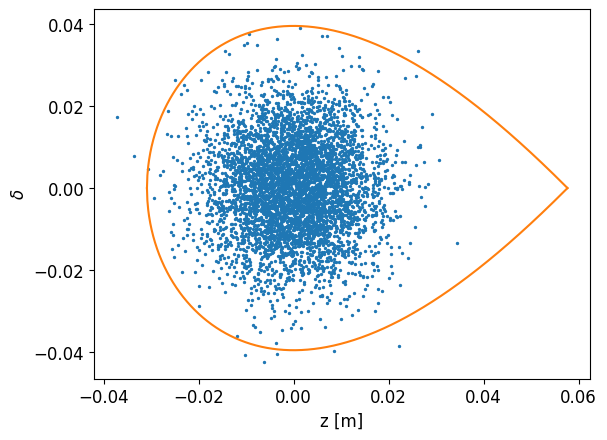

----- Build RCS line -----
----- Insert particle monitors and apertures -----
Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.9290241576694225e-05
ey = 2.5140357340440034e-05
es = 0.021970508693674142
----- Tracking results at extraction -----
ex = 0.00010889760417865299
ey = 2.344212263341222e-05
es = 0.02007021164194671
tr = 0.9438
----- Growth at extraction -----
ex = 271.78800281832116
ey = -6.755014195029292
es = -8.649308389817012


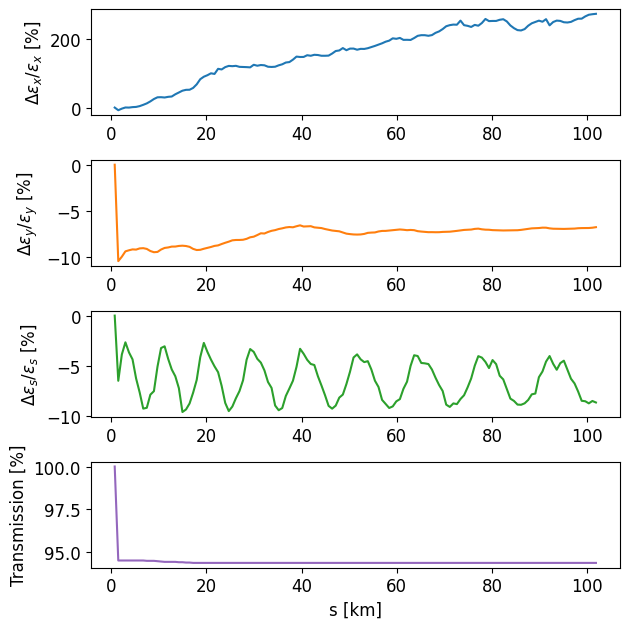

----- Generating particle distribution -----
*** Maximum RMS bunch length 0.03634698528852932m.


RFBucketMatcher: failed to converge with Brent method, continuing with Newton-Raphson method.


... distance to target bunch length: 4.5806e-04
... distance to target bunch length: 2.6289e-02
... distance to target bunch length: 1.4665e-04
... distance to target bunch length: 2.5275e-04
... distance to target bunch length: 2.1001e-07
--> Bunch length: 0.009053732530532672
--> Emittance: 0.2695584752465458
Emittance x at injection, before 2nd order matching 2.5632339260809832e-05
Emittance s at injection 0.023506512923107716
Matched distribution adapted to second order with max delta: 0.009800327634535802
----- Initial particle distribution and separatrix -----


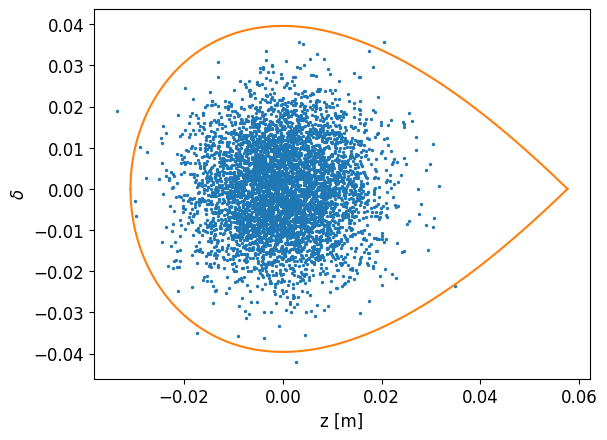

----- Build RCS line -----
----- Insert particle monitors and apertures -----
Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.9109079176215167e-05
ey = 2.582473090605188e-05
es = 0.021155242415679457
----- Tracking results at extraction -----
ex = 0.0008453888753952515
ey = 2.5446761410996973e-05
es = 0.020249658185851286
tr = 0.9544
----- Growth at extraction -----
ex = 2804.2102990534067
ey = -1.4635950958402182
es = -4.280661086431167


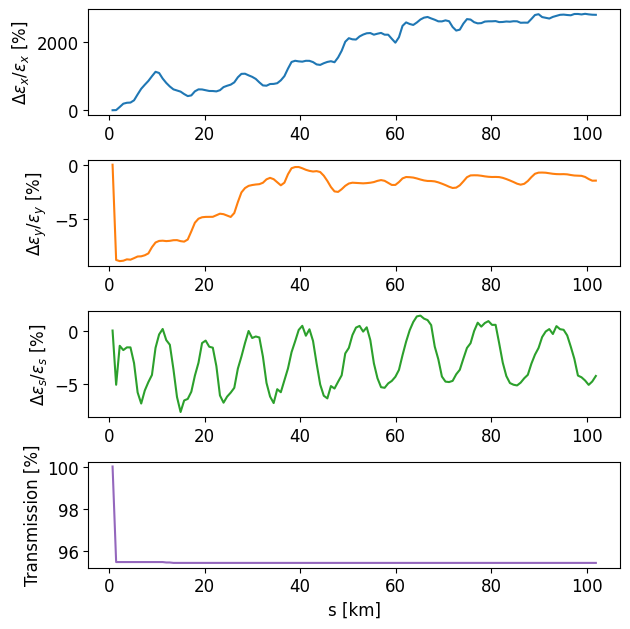

Study for RCS1, 32 arcs


Loading line from dict: 100%|██████████| 43/43 [00:00<00:00, 9319.23it/s]

Done loading line from dict.           
range(0, 544)
----- Generating particle distribution -----
*** Maximum RMS bunch length 0.03634698502024826m.



RFBucketMatcher: failed to converge with Brent method, continuing with Newton-Raphson method.


... distance to target bunch length: 4.8345e-04
... distance to target bunch length: 2.6289e-02
... distance to target bunch length: 1.4665e-04
... distance to target bunch length: 2.5275e-04
... distance to target bunch length: 2.1001e-07
--> Bunch length: 0.009053732530532679
--> Emittance: 0.3168478051307226
Emittance x at injection, before 2nd order matching 2.538616625647708e-05
Emittance s at injection 0.02986172212020704
Matched distribution adapted to second order with max delta: 0.011010769481695793
----- Initial particle distribution and separatrix -----


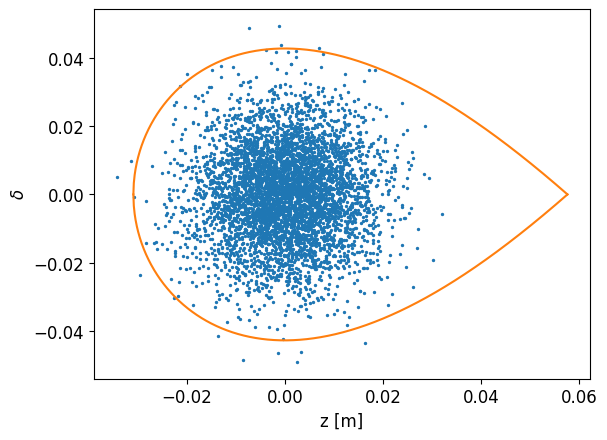

----- Build RCS line -----
----- Insert particle monitors and apertures -----
Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.7981850168251654e-05
ey = 2.4985238836456138e-05
es = 0.029508369251406045
----- Tracking results at extraction -----
ex = 2.5434352241450293e-05
ey = 2.485682014315873e-05
es = 0.030258774689740562
tr = 0.9974
----- Growth at extraction -----
ex = -9.104108239746651
ey = -0.5139782498698078
es = 2.5430257834351893


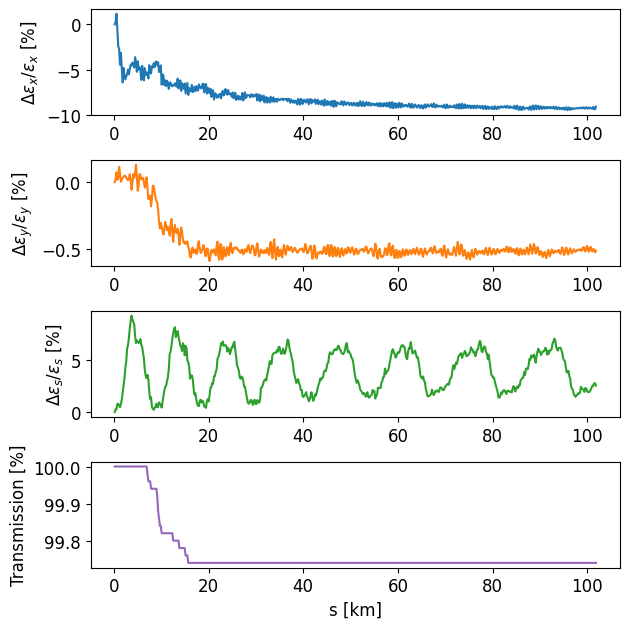

----- Generating particle distribution -----
*** Maximum RMS bunch length 0.03634698502024826m.


RFBucketMatcher: failed to converge with Brent method, continuing with Newton-Raphson method.


... distance to target bunch length: 4.8345e-04
... distance to target bunch length: 2.6289e-02
... distance to target bunch length: 1.4665e-04
... distance to target bunch length: 2.5275e-04
... distance to target bunch length: 2.1001e-07
--> Bunch length: 0.009053732530532679
--> Emittance: 0.3168478051307226
Emittance x at injection, before 2nd order matching 2.5189310549675767e-05
Emittance s at injection 0.02930038836862582
Matched distribution adapted to second order with max delta: 0.011249931566702065
----- Initial particle distribution and separatrix -----


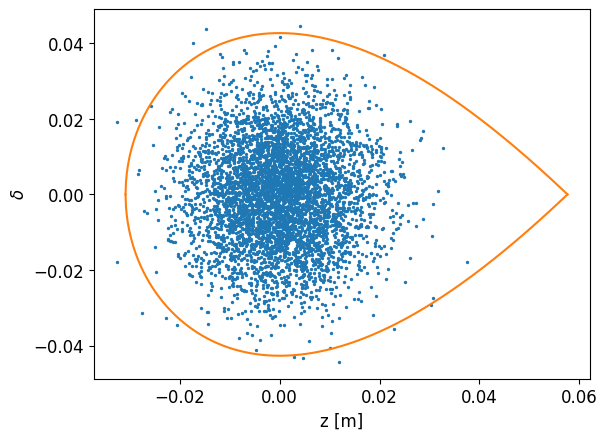

----- Build RCS line -----
----- Insert particle monitors and apertures -----
Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.778797377680196e-05
ey = 2.503594785647438e-05
es = 0.02910580722995948
----- Tracking results at extraction -----
ex = 2.8841496315782117e-05
ey = 2.4882771947218943e-05
es = 0.03017113779617569
tr = 0.9984
----- Growth at extraction -----
ex = 3.7912895248938963
ey = -0.6118238867310375
es = 3.6601993471585716


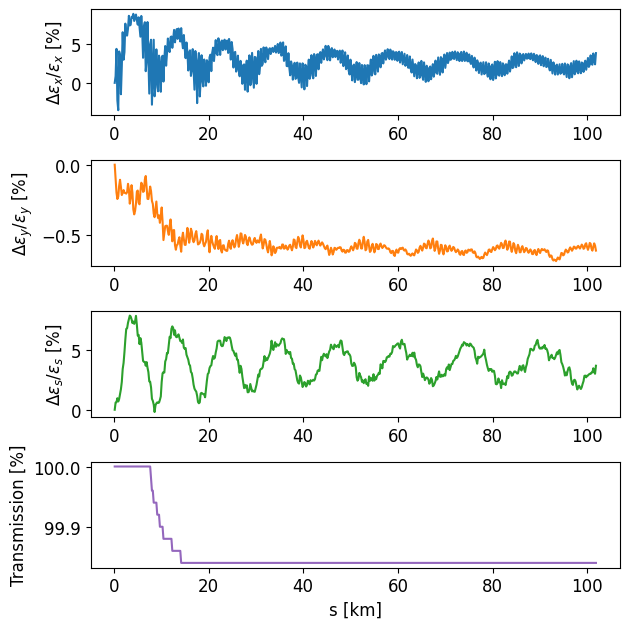

In [ ]:
rcs_name = 'RCS1'
narcs = [
    '8',
    '32'
    ]

adapt_part = True
adapt_per = 80
n_sigma = 5
method = 'var_ref'
RF_tuning = False
plt_twiss = False
plt_sepa = True

n_factor = 1
n_track = 1

res = {}
for n_a in narcs:
    res[n_a] = {}

    print(f'Study for {rcs_name}, {n_a} arcs')
    file_input = rcs_files[rcs_name][n_a]['file_arc']
    file_geo = rcs_files[rcs_name][n_a]['file_geo']

    line_arc = xt.Line.from_json(file_input)
    rcs = RingGeometry(file_geo)

    sigma_z = rcs_files[rcs_name][n_a]['sigma_z']
    n_turn_rcs = input[rcs_name]['n_turn_rcs']
    t_acc = input[rcs_name]['t_acc']

    n_range = range(int(int(n_a)*n_turn_rcs/n_factor))
    print(n_range)

    track = TrackingRCS(
        line = line_arc,
        rcs = rcs,
        n_turn_rcs = n_turn_rcs,
        n_part = n_part,
        nemitt_x = nemitt_x,
        nemitt_y = nemitt_y,
        sigma_z = sigma_z,
        t_acc = t_acc,
        ramp = False,
        n_sigma = n_sigma,
        method = method,
        RF_tuning = RF_tuning,
        plt_twiss = plt_twiss,
        plt_sepa = plt_sepa,
        adapt_part = adapt_part,
        adapt_percentile = adapt_per,
        n_range = n_range
    )

    track_ramp = TrackingRCS(
        line = line_arc,
        rcs = rcs,
        n_turn_rcs = n_turn_rcs,
        n_part = n_part,
        nemitt_x = nemitt_x,
        nemitt_y = nemitt_y,
        sigma_z = sigma_z,
        t_acc = t_acc,
        ramp = True,
        n_sigma = n_sigma,
        method = method,
        RF_tuning = RF_tuning,
        plt_twiss = plt_twiss,
        plt_sepa = plt_sepa,
        adapt_part = adapt_part,
        adapt_percentile = adapt_per,
        n_range = n_range
    )

    res[n_a]['noramp'] = track
    res[n_a]['ramp'] = track_ramp


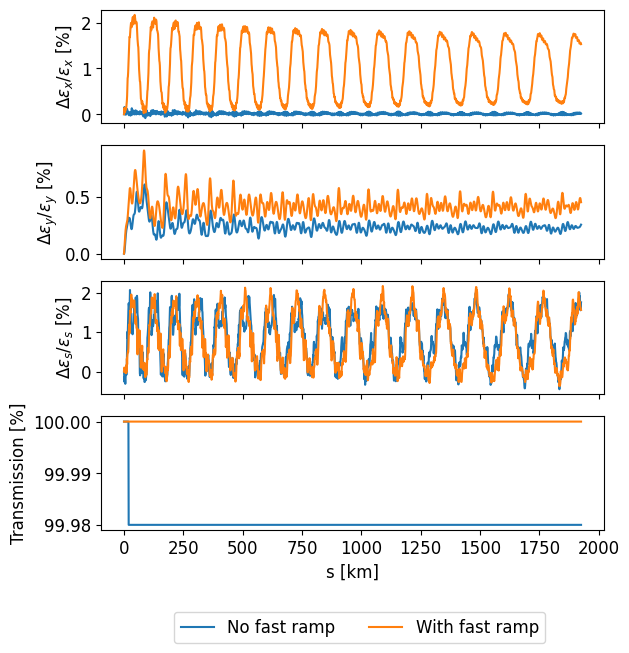

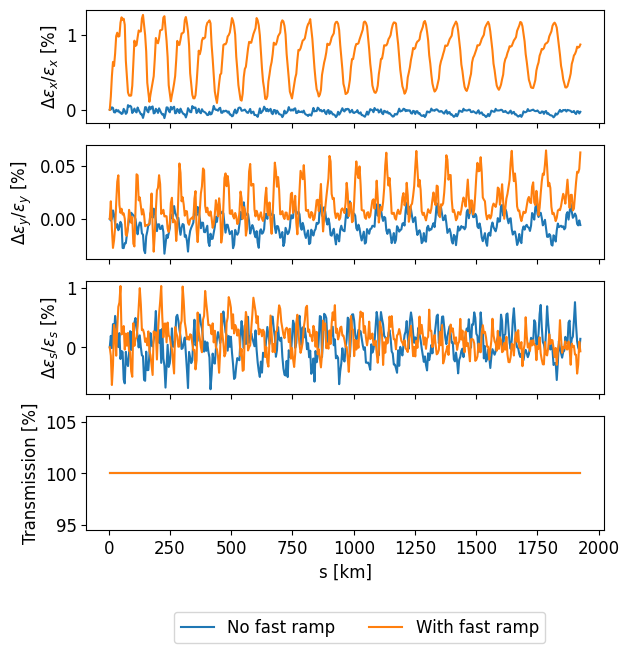

In [ ]:
fig32_ramp = plot_emit_2rcs(
    res['32']['noramp'].track_res,  
    res['32']['ramp'].track_res, 
    'No fast ramp', 
    'With fast ramp')
fig8_ramp = plot_emit_2rcs(
    res['8']['noramp'].track_res,  
    res['8']['ramp'].track_res, 
    'No fast ramp', 
    'With fast ramp')

In [8]:
fig_path = f'/mnt/c/muco/Results/figures/chap6/tracking_v2/'
save_fig = True

if save_fig:
    fig32_ramp.savefig(fig_path+f'tracking_{rcs_name}_32arc_ramp_{method}')
    fig8_ramp.savefig(fig_path+f'tracking_{rcs_name}_8arc_ramp_{method}')

In [46]:
def json_serialize(obj):
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    return obj

data = {
    # 'noramp' : res['32']['noramp'].track_res,
    'ramp' : res['8']['ramp'].track_res
        }
with open(fig_path+f"tracking_{rcs_name}_8arc.json", "w") as f:
    json.dump(data, f, default=json_serialize)

Effect of RF tuning on RCS2

Study for RCS2, 32 arcs


Loading line from dict: 100%|██████████| 75/75 [00:00<00:00, 13329.92it/s]


Done loading line from dict.           
----- Generating particle distribution -----
*** Maximum RMS bunch length 0.03634703409068596m.


/home/ls276867/.venvs/xsuite/lib/python3.11/site-packages/scipy/integrate/_quadpack_py.py:1264: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  quad_r = quad(f, low, high, args=args, full_output=self.full_output,
RFBucketMatcher: failed to converge with Brent method, continuing with Newton-Raphson method.


... distance to target bunch length: 4.0793e-03
... distance to target bunch length: 2.8358e-02
... distance to target bunch length: 6.5582e-05
... distance to target bunch length: 1.6923e-04
... distance to target bunch length: 4.6239e-08
--> Bunch length: 0.006985164303895585
--> Emittance: 0.2953045360677459
Emittance x at injection, before 2nd order matching 2.4551617705393535e-05
Emittance s at injection 0.027401218741083467
----- Initial particle distribution and separatrix -----


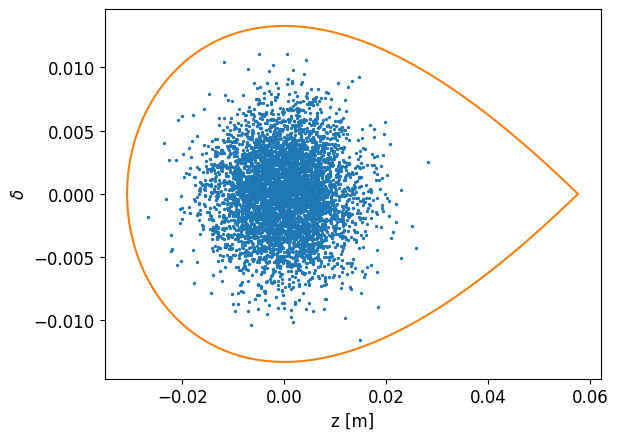

----- Build RCS line -----
----- Insert particle monitors and apertures -----


Slicing line: 100%|██████████| 133760/133760 [00:00<00:00, 151732.48it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.4599892194148188e-05
ey = 2.470399510402143e-05
es = 0.02248246536082763
----- Tracking results at extraction -----
ex = 1.9763792005994923e-05
ey = 1.9823487325447197e-05
es = 0.18315097128922464
tr = 0.8024
----- Growth at extraction -----
ex = -19.65903000706513
ey = -19.7559453765426
es = 714.6391792438303


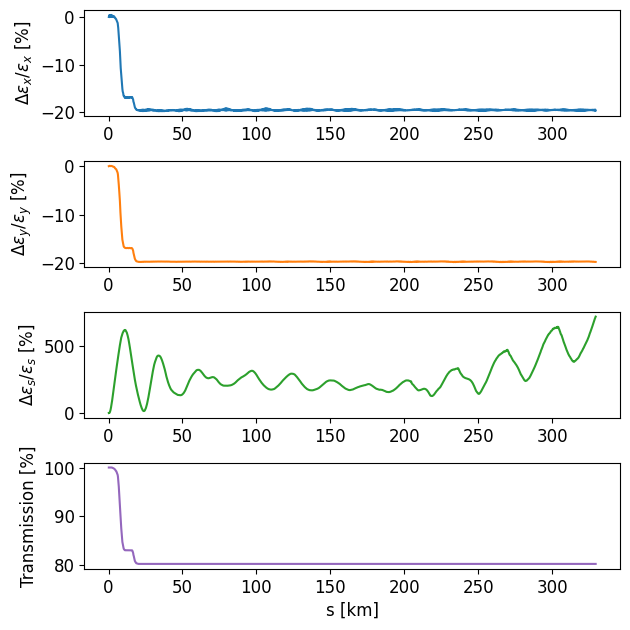

----- Generating particle distribution -----
*** Maximum RMS bunch length 0.03634703409068596m.


RFBucketMatcher: failed to converge with Brent method, continuing with Newton-Raphson method.


... distance to target bunch length: 4.0793e-03
... distance to target bunch length: 2.8358e-02
... distance to target bunch length: 6.5582e-05
... distance to target bunch length: 1.6923e-04
... distance to target bunch length: 4.6239e-08
--> Bunch length: 0.006985164303895585
--> Emittance: 0.2953045360677459
Emittance x at injection, before 2nd order matching 2.5287674891041724e-05
Emittance s at injection 0.02820345183225203
----- Initial particle distribution and separatrix -----


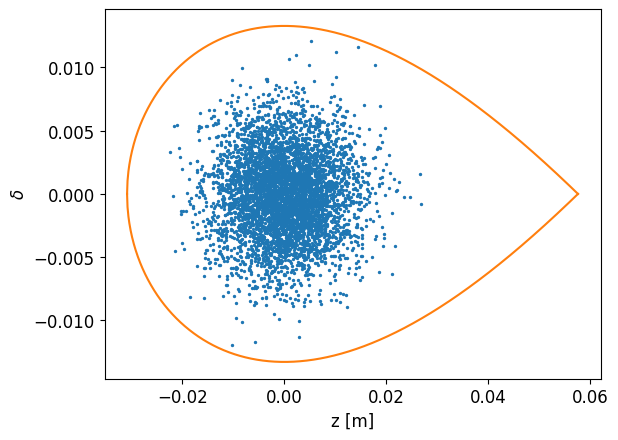

----- Build RCS line -----
----- Insert particle monitors and apertures -----


Slicing line: 100%|██████████| 137280/137280 [00:00<00:00, 260107.18it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.5280044664047978e-05
ey = 2.5221325970489775e-05
es = 0.02794523114803912
----- Tracking results at extraction -----
ex = 2.5277888535997968e-05
ey = 2.5140959993331763e-05
es = 0.0283889411163548
tr = 0.9982
----- Growth at extraction -----
ex = -0.008528972470830702
ey = -0.31864295022412537
es = 1.5877842125017316


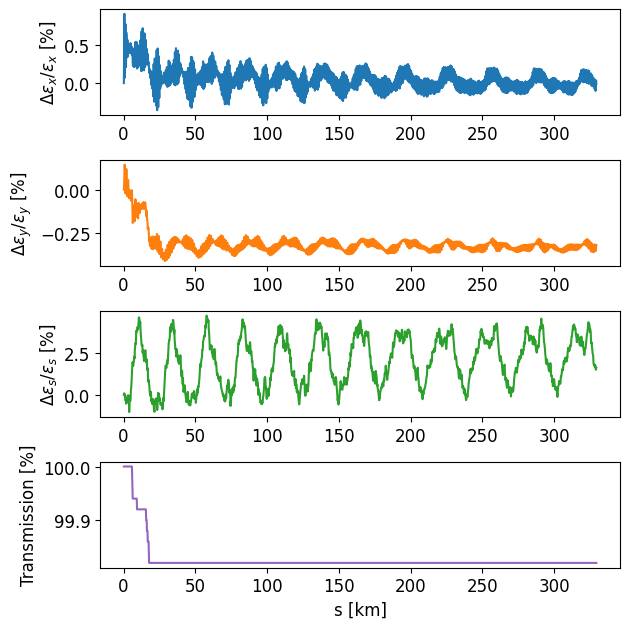

In [ ]:
rcs_name = 'RCS2'
n_a = '32'

adapt_part = False
ramp = False
n_sigma = 5
method = 'var_ref'
RF_tuning = False
plt_twiss = False
plt_sepa = True
n_part = 5000

print(f'Study for {rcs_name}, {n_a} arcs')
file_input = rcs_files[rcs_name][n_a]['file_arc']
file_geo = rcs_files[rcs_name][n_a]['file_geo']

line_arc = xt.Line.from_json(file_input)
rcs = RingGeometry(file_geo)

sigma_z = rcs_files[rcs_name][n_a]['sigma_z']
n_turn_rcs = input[rcs_name]['n_turn_rcs']
t_acc = input[rcs_name]['t_acc']


track_k = TrackingRCS(
    line = line_arc,
    rcs = rcs,
    n_turn_rcs = n_turn_rcs,
    n_part = n_part,
    nemitt_x = nemitt_x,
    nemitt_y = nemitt_y,
    sigma_z = sigma_z,
    t_acc = t_acc,
    ramp = ramp,
    n_sigma = n_sigma,
    method = 'var_k',
    RF_tuning = False,
    plt_twiss = plt_twiss,
    plt_sepa = plt_sepa,
    adapt_part = adapt_part,
    adapt_percentile = adapt_per,
)

track_k_tuning = TrackingRCS(
    line = line_arc,
    rcs = rcs,
    n_turn_rcs = n_turn_rcs,
    n_part = n_part,
    nemitt_x = nemitt_x,
    nemitt_y = nemitt_y,
    sigma_z = sigma_z,
    t_acc = t_acc,
    ramp = ramp,
    n_sigma = n_sigma,
    method = 'var_k',
    RF_tuning = True,
    plt_twiss = plt_twiss,
    plt_sepa = plt_sepa,
    adapt_part = adapt_part,
    adapt_percentile = adapt_per,
)


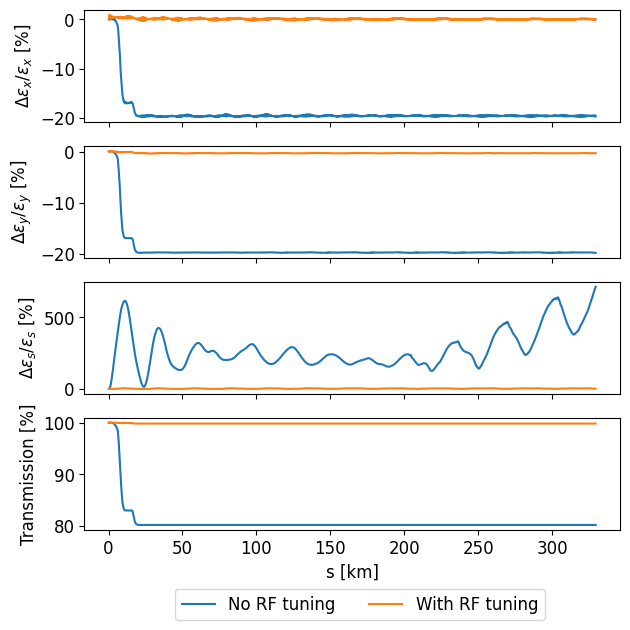

In [ ]:
fig_tuning = plot_emit_2rcs(
    track_k.track_res,  
    track_k_tuning.track_res, 
    'No RF tuning', 
    'With RF tuning')

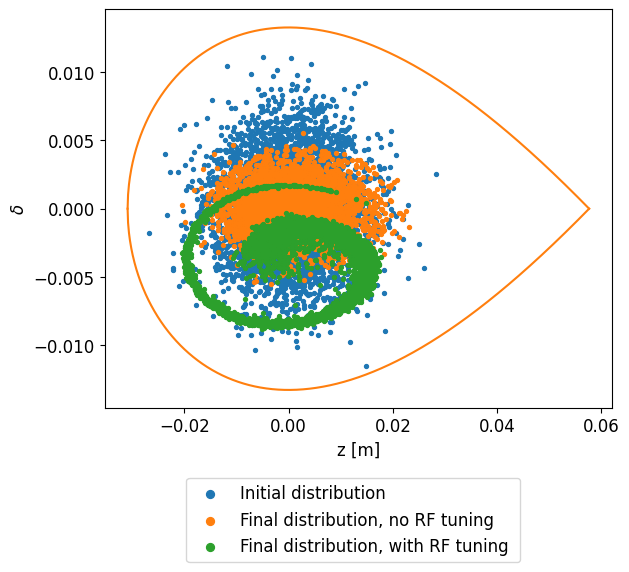

In [ ]:
folder = f'/mnt/c/muco/Results/figures/chap6/tracking_v2/'
part0 = track_k.particles0
# part_ref = track_ref.particles
part_k = track_k.particles
part_k_tuning = track_k_tuning.particles

mask_k = track_k_tuning.particles.state >= 1 
mask = track_k.particles.state >= 1 

fig_part0 = plt.figure(figsize=(6.4,4.8))
machine_rf_bucket = track_k.rf_bucket
ufp = machine_rf_bucket.z_ufp
xx = np.linspace(machine_rf_bucket.z_left, machine_rf_bucket.z_right, 1000)
yy = machine_rf_bucket.separatrix(xx)
plt.plot((xx-machine_rf_bucket.z_sfp), yy, color='tab:orange')
plt.plot((xx-machine_rf_bucket.z_sfp), -yy, color='tab:orange')
plt.scatter(part0.zeta, part0. delta, s=8, label=f'Initial distribution')
plt.scatter(part_k_tuning.zeta[mask_k], part_k_tuning.delta[mask_k], s=8, label=f'Final distribution, no RF tuning ')
plt.scatter(part_k.zeta[mask], part_k.delta[mask], s=8, label=f'Final distribution, with RF tuning ')
plt.xlabel('z [m]')
plt.ylabel(r'$\delta$')
fig_part0.legend(
    loc='lower center', 
    bbox_to_anchor=(0.56, -0.2),
    markerscale=2
    )   
plt.tight_layout()
plt.show()

fig_track = track_k.fig_tracking
fig_part0.savefig(folder+f'{rcs_name}_{n_a}_part_RFtuning', bbox_inches='tight')
fig_track.savefig(folder+f'{rcs_name}_{n_a}_tracking_noRFtuing',  bbox_inches='tight')
fig_tuning.savefig(folder+f'{rcs_name}_{n_a}_tracking_no_wih_RFtuing',  bbox_inches='tight')